# Sparklines

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Tiny, word-sized line charts with no axes, set next to numbers in a table or text (the term was coined by Edward Tufte). They add the shape of the recent trend to each figure at very little cost in space.

## When to use

- Dashboards and tables where each row needs trend context
- Show general shape (up, down, volatile) for many metrics at once

## Avoid when

- Readers need actual values or comparisons between rows' scales
- The trend is the main story (give it a full chart)

## Alternatives

- Small multiples
- KPI stat tile with delta

## Design tips

- Mark the last point with a dot and show the latest value as text

## Example

Six business KPIs with their latest value and a 30-day sparkline.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(30)
# name: (starting level, daily drift %, daily noise %)
kpis = {"Revenue ($k)": (102, 0.6, 1.5), "Orders": (1000, 0.3, 1.5),
        "New users": (980, -0.2, 2.0), "Churn rate (%)": (2.5, 0.3, 1.5),
        "Avg. basket ($)": (66, -0.1, 1.0), "NPS": (40, 0.15, 1.2)}
series = {k: base * np.exp(np.cumsum(rng.normal(d, n, 30)) / 100)
          for k, (base, d, n) in kpis.items()}
df = pd.DataFrame(series)
df.tail()

,Revenue ($k),Orders,New users,Churn rate (%),Avg. basket ($),NPS
25,129.825177,1098.214519,932.923679,2.837273,60.499583,40.591208
26,130.167182,1144.342051,909.961347,2.871082,60.376157,41.739158
27,131.955920,1150.626329,923.070904,2.889779,59.762466,41.666694
28,131.702207,1132.067662,925.599081,2.954948,60.649425,41.642199
29,130.698877,1109.019895,937.722330,2.993805,61.790504,42.419541


### Plot

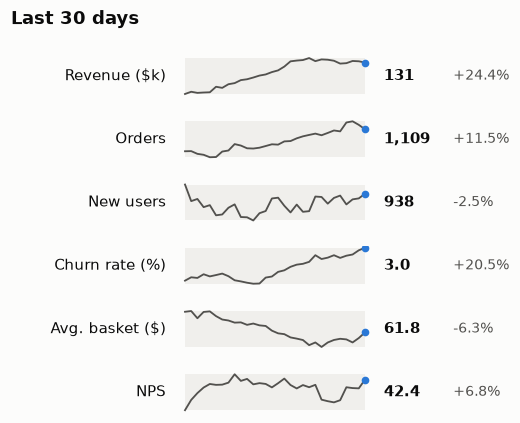

In [3]:
fig, axes = plt.subplots(len(df.columns), 1, figsize=(5, 4.2))
for ax, col in zip(axes, df.columns):
    s = df[col]
    change = s.iloc[-1] / s.iloc[0] - 1
    ax.plot(s.values, color="#52514e", linewidth=1.2)
    ax.plot(len(s) - 1, s.iloc[-1], "o", color=PALETTE[0], markersize=4)
    ax.fill_between(range(len(s)), s.min(), s.max(), color="#f0efec", linewidth=0)
    ax.axis("off")
    ax.text(-0.05, 0.5, col, transform=ax.transAxes, ha="right", va="center", fontsize=10)
    ax.text(1.05, 0.5, f"{s.iloc[-1]:,.0f}" if s.iloc[-1] >= 100 else f"{s.iloc[-1]:.1f}", transform=ax.transAxes, ha="left",
            va="center", fontsize=10, fontweight="bold")
    ax.text(1.40, 0.5, f"{change:+.1%}", transform=ax.transAxes, ha="left",
            va="center", fontsize=9, color="#52514e")
fig.suptitle("Last 30 days", x=0.02, ha="left", fontweight="bold")
fig.subplots_adjust(left=0.32, right=0.68, hspace=0.6)
plt.show()

---
Standalone script: [`sparklines.py`](sparklines.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)